# Figure 1

Draws the quantitative panels of Figure 1 from the source data.

Data: `Wilhelm_SourceData.xlsx` (one worksheet per panel) and the `Wilhelm_SourceData_*.parquet` / `*.csv` files of the figshare deposit (column descriptions in the deposit's `README.md`). Set `FIGSHARE_ARTICLE_ID` in the next cell (or as environment variable; while the article is private also `FIGSHARE_TOKEN`) to download the files into `./data`, or set `SOURCE_DATA_DIR` to a local copy of the deposit.

In [1]:
import source_data as sd
from source_data import fetch, readme, table

# figshare article with the source data (https://doi.org/10.6084/m9.figshare.34601982); alternatively set the environment variable
# FIGSHARE_ARTICLE_ID, or SOURCE_DATA_DIR to a local copy of the files. While the article is private, set FIGSHARE_TOKEN.
sd.FIGSHARE_ARTICLE_ID = sd.FIGSHARE_ARTICLE_ID or ""

In [2]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

plt.rcParams['pdf.fonttype'] = 42
DATA = Path('data')
DATA.mkdir(exist_ok=True)
FIG_DIR = Path('regenerated_panels') / 'Fig1'
FIG_DIR.mkdir(parents=True, exist_ok=True)


readme('Fig1')

,Figure,Panel,Worksheet,figshare file(s),Content,Tables in worksheet (top to bottom)
0,Fig. 1,a,Fig1a,NaN,Number of peptides per PTM category in the Pro...,Fig1a
1,Fig. 1,b,Fig1b,NaN,Summary statistics of the ProteomeTools data u...,Fig1b
2,Fig. 1,c,Fig1c,NaN,Recovery rate (%) per PTM package and fragment...,Fig1c
3,Fig. 1,d,Fig1d,NaN,Peak lists of the mirror spectrum (top: modifi...,Fig1d; Fig1d_parameters
4,Fig. 1,e,NaN,Wilhelm_SourceData_Fig1e.parquet; Wilhelm_Sour...,Spectral angle of each modified/unmodified spe...,NaN


## Panel a — PTM categories

Number of peptides per PTM category in the ProteomeTools PTM dataset (pie chart).

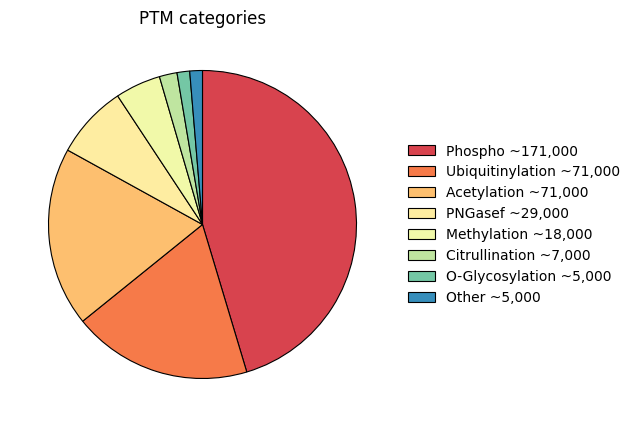

,PTM_category,approximate_count
0,Phospho,171000
1,Ubiquitinylation,71000
2,Acetylation,71000
3,PNGasef,29000
4,Methylation,18000
5,Citrullination,7000
6,O-Glycosylation,5000
7,Other,5000


In [3]:
a = table('Fig1a')
fig, ax = plt.subplots(figsize=(5, 5))
wedges, _ = ax.pie(a['approximate_count'],
       startangle=90, counterclock=False, colors=sns.color_palette('Spectral', len(a)),
       wedgeprops=dict(edgecolor='black', linewidth=0.8))
ax.legend(wedges, [f"{l} ~{v:,}" for l, v in zip(a.PTM_category, a.approximate_count)], loc='center left', bbox_to_anchor=(1, 0.5), frameon=False)
ax.set_title('PTM categories')
for ext in ('pdf', 'png'):
    plt.savefig(FIG_DIR / f'Fig1a.{ext}', dpi=300, bbox_inches='tight')
plt.show()
a

## Panel b — ProteomeTools summary

Summary statistics of the ProteomeTools data used.

In [4]:
table('Fig1b')

,metric,value,unit
0,PSMs,50000000,count
1,Modified peptides,750000,count
2,Raw files,3945,count
3,Pools,1219,count
4,Packages,33,count
5,Gradient time,164,days


## Panel c — Recovery rates

Recovery rate (%) per PTM package and fragmentation method / collision energy. NA cells (black): acquisitions not performed (HCD+23.0 for Phosphorylation (S) and (T)).

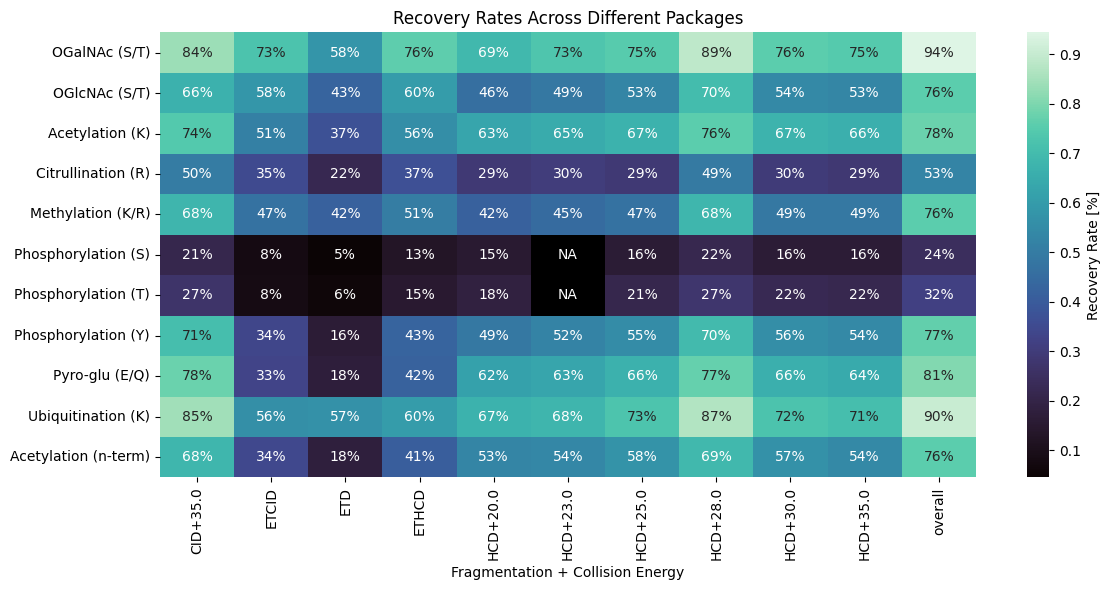

In [5]:
c = table('Fig1c').set_index('PTM').drop(columns='package')
c.columns = [col.replace(' recovery_rate_%', '') for col in c.columns]
fig, ax = plt.subplots(figsize=(12, 6))
sns.heatmap(c / 100, annot=True, fmt='.0%', cmap=sns.color_palette('mako', as_cmap=True),
            cbar_kws={'label': 'Recovery Rate [%]'}, ax=ax)
ax.set_facecolor('black')  # NA cells (acquisition not performed)
for (i, j), v in np.ndenumerate(c.values):
    if np.isnan(v):
        ax.text(j + 0.5, i + 0.5, 'NA', color='white', ha='center', va='center')
ax.set_xlabel('Fragmentation + Collision Energy')
ax.set_ylabel('')
ax.set_title('Recovery Rates Across Different Packages')
plt.xticks(rotation=90)
plt.tight_layout()
for ext in ('pdf', 'png'):
    plt.savefig(FIG_DIR / f'Fig1c.{ext}', dpi=300, bbox_inches='tight')
plt.show()

## Panel d — Mirror spectrum (lysine ubiquitination)

Peak lists of the modified (top) and unmodified (bottom) spectrum with b/y annotation. Intensities are relative to the most intense b/y fragment ion; peaks above 100% (unfragmented precursor) are truncated at 100%. Spectral angle and retention-time difference from table `Fig1d_parameters`.

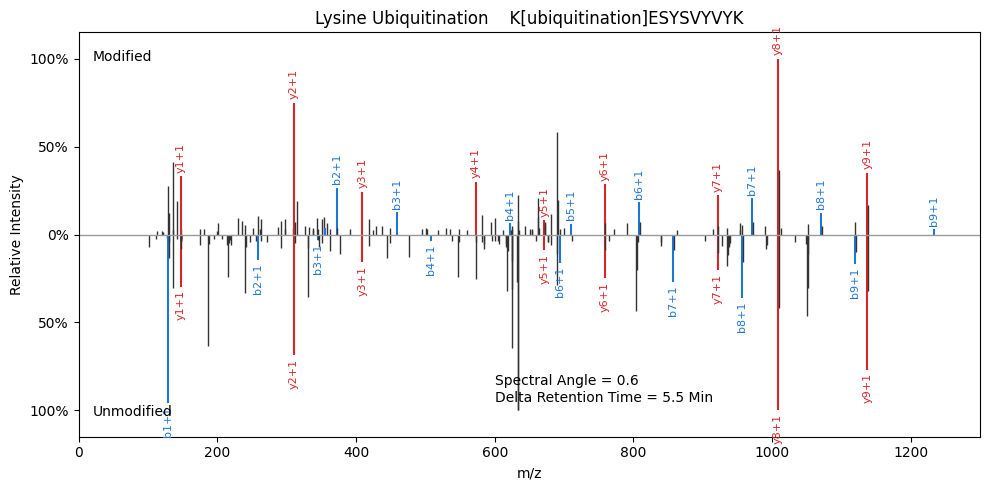

parameter
Peptide                                                           K[UNIMOD:121]ESYSVYVYK vs KESYSVYVYK
Fragmentation                                                                                      HCD
Precursor charge                                                                                     2
Normalised collision energy (aligned), modified                                                  0.319
Normalised collision energy (aligned), unmodified                                                0.294
Spectral angle (Prosit-annotated b/y ions)                                                         0.6
Delta retention time (aligned) [min]                                                               5.5
Annotation                                           b/y fragment ions without neutral losses; anno...
Name: value, dtype: object

In [6]:
d = table('Fig1d')
params = table('Fig1d_parameters').set_index('parameter')['value']
colors = {'b': '#1f77d4', 'y': '#d62728'}
# scaled to the most intense b/y fragment; unfragmented precursor peaks (>100%) are truncated
d['plot_int'] = d['relative_intensity_to_base_fragment_%'].clip(upper=100)
fig, ax = plt.subplots(figsize=(10, 5))
for role, sign in [('modified (top)', 1), ('unmodified (bottom)', -1)]:
    s = d[d.spectrum == role]
    for _, p in s.iterrows():
        ion = p.ion_type if isinstance(p.annotation, str) and p.ion_type in colors else None
        ax.vlines(p.mz, 0, sign * p['plot_int'], color=colors.get(ion, '0.2'), lw=1.5 if ion else 1)
        if ion and p.annotation.endswith('+1'):
            ax.text(p.mz, sign * (p['plot_int'] + 2), p.annotation, color=colors[ion],
                    rotation=90, ha='center', va='bottom' if sign > 0 else 'top', fontsize=8)
ax.axhline(0, color='0.6', lw=1)
ax.set_xlim(0, 1300)
ax.set_ylim(-115, 115)
ax.set_yticks([-100, -50, 0, 50, 100], ['100%', '50%', '0%', '50%', '100%'])
ax.set_xlabel('m/z')
ax.set_ylabel('Relative Intensity')
ax.text(20, 105, 'Modified', va='top')
ax.text(20, -105, 'Unmodified', va='bottom')
ax.text(600, -95, f"Spectral Angle = {params['Spectral angle (Prosit-annotated b/y ions)']}\n"
                  f"Delta Retention Time = {params['Delta retention time (aligned) [min]']} Min")
ax.set_title(f"Lysine Ubiquitination    {d.modified_sequence.iloc[0].replace('[UNIMOD:121]', '[ubiquitination]')}")
plt.tight_layout()
for ext in ('pdf', 'png'):
    plt.savefig(FIG_DIR / f'Fig1d.{ext}', dpi=300, bbox_inches='tight')
plt.show()
params

## Panel e — Spectral similarity between modified and unmodified peptides

Spectral angle of each modified/unmodified spectrum pair (same peptide sequence, precursor charge and fragmentation; |ΔNCE| < 0.01), split violins per PTM (HCD left, CID right). Violins: seaborn `violinplot(split=True, inner=None, bw_method=0.3)`, default `cut=2`. n labels = spectra carrying the modification per fragmentation (`Wilhelm_SourceData_Fig1e_n.csv`).

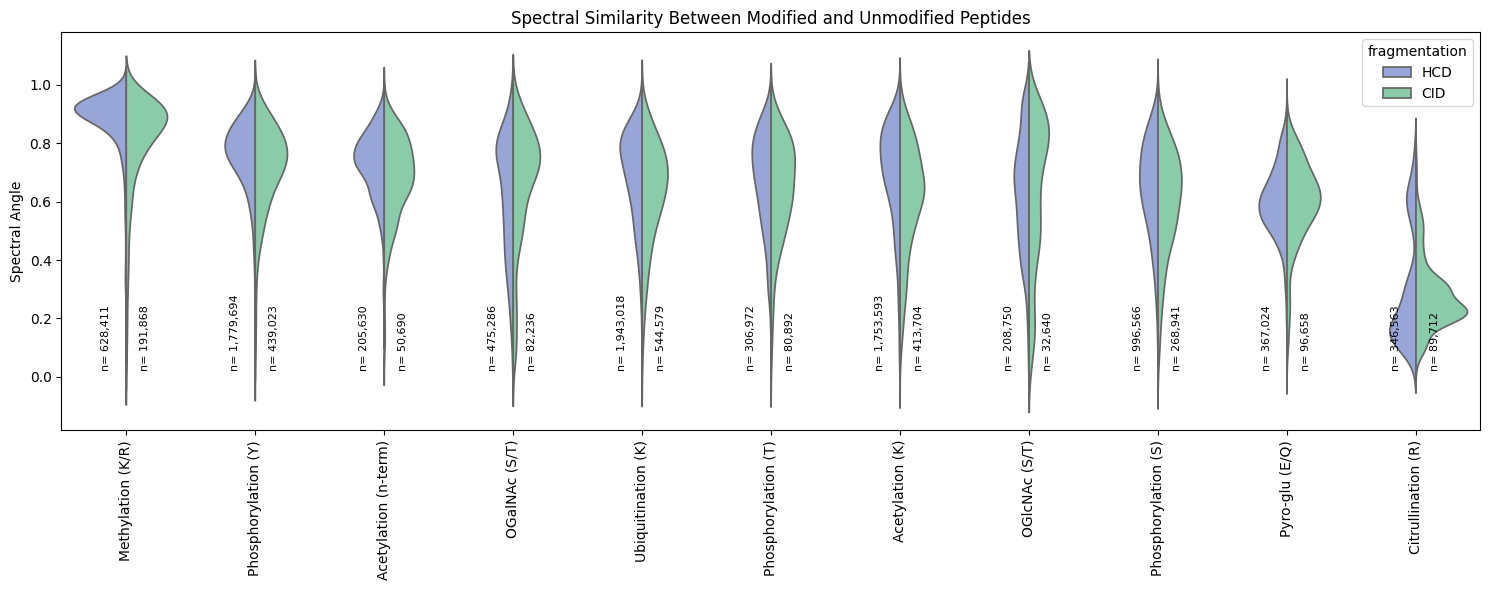

,PTM,modified_spectra_HCD (n label),modified_spectra_CID (n label),mod_unmod_pairs_HCD,mod_unmod_pairs_CID,median_spectral_angle
0,Methylation (K/R),628411,191868,20228,37938,0.881962
1,Phosphorylation (Y),1779694,439023,61181,98571,0.755128
2,Acetylation (n-term),205630,50690,3302,6825,0.717146
3,OGalNAc (S/T),475286,82236,7547,9119,0.697411
4,Ubiquitination (K),1943018,544579,85928,67380,0.693310
5,Phosphorylation (T),306972,80892,24628,20448,0.683512
6,Acetylation (K),1753593,413704,22985,22776,0.680402
7,OGlcNAc (S/T),208750,32640,1469,2543,0.662561
8,Phosphorylation (S),996566,268941,75869,65141,0.645585
9,Pyro-glu (E/Q),367024,96658,12892,17293,0.604198


In [7]:
e = pd.read_parquet(fetch('Wilhelm_SourceData_Fig1e.parquet'))
e_n = table('Fig1e_n')
order = e_n['PTM'].tolist()
fig, ax = plt.subplots(figsize=(15, 6))
sns.violinplot(data=e, x='PTM', y='spectral_angle', hue='fragmentation', hue_order=['HCD', 'CID'],
               split=True, inner=None, bw_method=0.3, order=order, palette=['#8da0e0', '#7fd6a8'], ax=ax)
for i, row in e_n.iterrows():
    ax.text(i - 0.15, 0.02, f"n= {row['modified_spectra_HCD (n label)']:,}", rotation=90, ha='center', va='bottom', fontsize=8)
    ax.text(i + 0.15, 0.02, f"n= {row['modified_spectra_CID (n label)']:,}", rotation=90, ha='center', va='bottom', fontsize=8)
ax.set_xlabel('')
ax.set_ylabel('Spectral Angle')
ax.set_title('Spectral Similarity Between Modified and Unmodified Peptides')
plt.xticks(rotation=90)
plt.tight_layout()
for ext in ('pdf', 'png'):
    plt.savefig(FIG_DIR / f'Fig1e.{ext}', dpi=300, bbox_inches='tight')
plt.show()
e_n